In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Постановка проблемы

Предположим, к нам попали данные исследований нескольких (пусть n=3) вакцин;  
В каждом исследовании собирались данные о респондентах, с которых через 1 / 10 / 100 часов собирали оценку самочувствия  

In [2]:
respondents = 1000

def make_research():
  research = {
      "gender": np.random.randint(0,2,respondents),            # 0 - m, 1 - f
      "age": np.random.normal(25.0,20.0,respondents),
      "height": np.random.normal(170.0,15.5,respondents),
      "weight": np.random.normal(65.0,25.0,respondents)
      }

  feeled_bad = 0                                                # считаем, сколько всего людей ощутили себя плохо

  part = np.random.randint(7,20,1)                              # доля респондентов, которые будут подвержены плохому самочувствию
  feeled_bad += part

  research["condition_after_1"] = np.random.normal(
      (5 *                                                      # мат. ожидание сдвигается: если бы исследования и не было, в среднем все ставили бы ровно 5,
       (respondents * (1 - part/100)) +                         # но теперь 5 в среднем поставят меньшее число людей
       1 * (respondents * part/100))                            # остальные захотят поставить 1
      / respondents,

      2.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 7 else -1       # будем считать, что люди более склонны иметь ухудшившееся самочувствие через какое-то время
  part = np.random.randint(
      7 - (got_better * 2),
      20 - (got_better * 5),
      1)
  feeled_bad += part

  research["condition_after_10"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      1.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 3 else -1       # будем считать, что люди более склонны иметь улучшившееся самочувствие через продолжительное время
  part = np.random.randint(
      7 - (got_better * 3),
      20 - (got_better * 7),
      1)
  feeled_bad += part

  research["condition_after_100"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      2.5,
      respondents
      )

  return research

In [3]:
researсh_1 = make_research()
researсh_2 = make_research()
researсh_3 = make_research()

# Задание

Мы хотим:
- проверить, что с данными все в порядке (т.к. данные генерили с помощью распределений, у нас могут быть отрицательные числа, которые надо исправить на 0, а также числа больше 10, которые надо исправить на 10) - построить гистограммы и почистить данные
- сравнить между собой результаты исследований разных вакцин и каким-либо образом представить сравнение исследований (т.е., к примеру, показать в одном пространстве сразу 3 исследования, пользуясь признаками "средняя оценка самочувствия после 1 часа", "средняя оценка самочувствия после 10 часов", "средняя оценка самочувствия после 100 часов"
- важно! обратите внимание на цвета, что вы используете

In [4]:
#проверка данных на допустимые значения и замена при необходимости

def clean(research):
    return {k: np.clip(v, 0, 10) if k.startswith("condition") else v
            for k, v in research.items()}

cleaned_reseach_1 = clean(researсh_1)
cleaned_reseach_2 = clean(researсh_2)
cleaned_reseach_3 = clean(researсh_3)

In [5]:
#еще заметила аномальные значения для возраста и веса
#для возраста сильно большое стрндартное отклонение при данном матожидании,
#поэтому появляются отрицательные возраста (или очень старые респонденты, но это еще приемлемо)
#то же самое для веса, большая сигма при выбранном матожид., поэтому появлвяются отрицательные веса
#есть два варианта решения – поправить настройки при генерации или тоже на что-то заменить аномальные значения,
#но определить "границы" аномальности – тоже непростой вопрос:)

#так как в задании эти параметры нигде учитывать не надо, я решила ничего и не делать.......

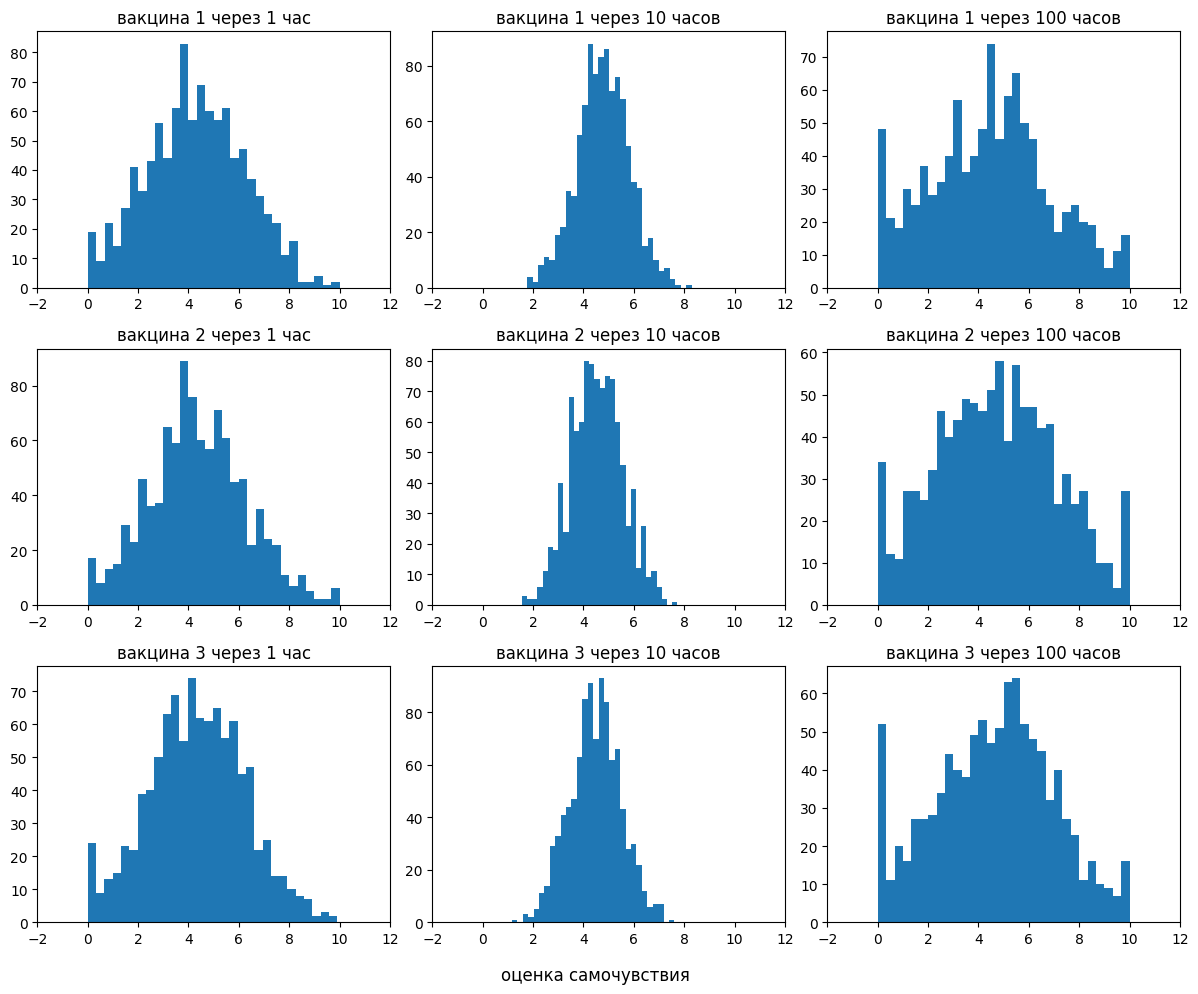

In [6]:
#проверим на гистограммах, что значения в норме, я выведу сразу 9 гистаграмм, чтобы одновременно посмотреть три ресерча (три вакцины) и три пробы

researches = [cleaned_reseach_1, cleaned_reseach_2, cleaned_reseach_3]
researches_labels = ["вакцина 1", "вакцина 2", "вакцина 3"]
timestamps_keys     = ["condition_after_1", "condition_after_10", "condition_after_100"]
time_labels   = ["через 1 час", "через 10 часов", "через 100 часов"]

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for i in range(3):
    for j in range(3):
        ax = axes[i, j]
        ax.hist(researches[i][timestamps_keys[j]], bins=30)
        ax.set_title(f"{researches_labels[i]} {time_labels[j]}")
        ax.set_xlim(-2, 12) #ставлю такие границы, чтобы везде одинаковые оси были и не зависели от значений в выборке + проверить, что нет выбросов за 0 и 10


fig.supxlabel("оценка самочувствия")


plt.tight_layout()
plt.show()

In [54]:
def plots(researches,
          labels=researches_labels,
          time_labels=time_labels,
          keys=timestamps_keys):
    colors = ["#0072B2", "#D55E00", "#009E73"] #цвета для дальтоников

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    #средние
    for research, label, color in zip(researches, labels, colors):
        means = [research[k].mean() for k in keys]
        ax1.plot(
            time_labels,
            means,
            "o-",
            color=color,
            label=label
                 )

    ax1.set_ylim(4, 5) #чтобы не схлопывались в одну линию выбираю масштаб курпнее
    ax1.set_xlabel("Время после инъекции")
    ax1.set_ylabel("Средняя оценка самочувствия")
    ax1.set_title("Средние оценки самочувствия после вакцин (через n часов)")
    ax1.legend()
    ax1.grid(alpha=0.5)

    #облако оценок
    for i, (research, label, color) in enumerate(zip(researches, labels, colors)):
        for j, k in enumerate(keys):
            vals = research[k]
            x = j + (i - 1) * 0.2 + np.random.uniform(-0.06, 0.06, len(vals))
            ax2.scatter(
                x,
                vals,
                s=5,
                color=color,
                alpha=0.12,
                label=label if j == 0 else None)

    ax2.set_xticks([0, 1, 2])
    ax2.set_xticklabels(time_labels)
    ax2.set_ylim(-0.5, 10.5)
    ax2.set_xlabel("Время после инъекции")
    ax2.set_ylabel("Оценка самочувствия")
    ax2.set_title("Облако оценок")
    ax2.legend(markerscale=4)
    ax2.grid(alpha=0.5)

    plt.tight_layout()
    plt.show()

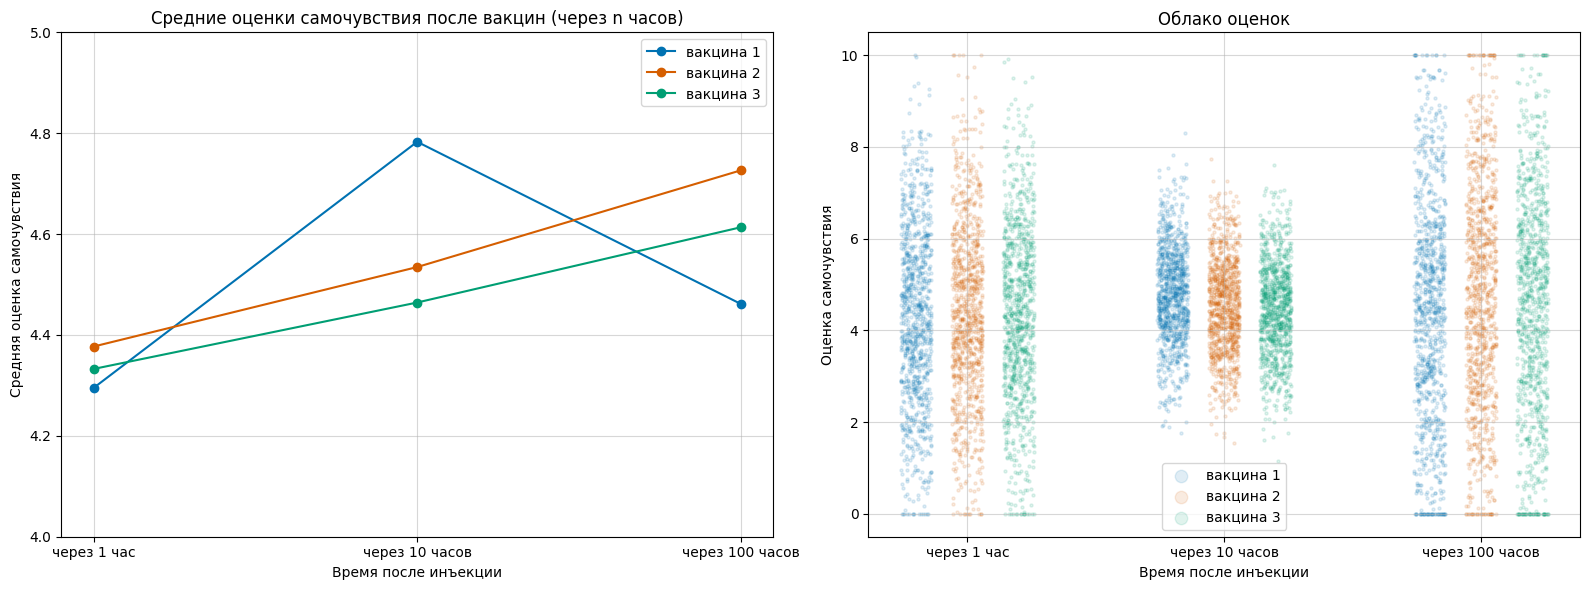

In [53]:
plots(researches)

In [ ]:
#я построила график с облаком оценок, чтобы увидеть разброс самочувствия пациентов,
#из него мы можем заключить, что через 10 часов все в среднем чувствуют себя одинаково "удовлетворительно"
#вне зависимости от вакцины
#мне кажется, это интересно

#для первого графика выбрала ось оу от 4 до 5, чтобы было лучше видно.
#здесь интересно, что хоть вакцина 1 и показывает результат сильно лучше других через 10 часов, через 1 и 100 часов она проигрывает